In [2]:
print('hola')

hola


In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
import os

ruta = '../data/raw/accidentes.csv'

print(f"Existe: {os.path.exists(ruta)}")
print(f"Tamaño: {os.path.getsize(ruta)} bytes")

with open(ruta, 'rb') as f:
    firma = f.read(8)
    print(f"Primeros bytes (hex): {firma.hex()}")
    print(f"Primeros bytes (texto): {firma}")

Existe: True
Tamaño: 46524403 bytes
Primeros bytes (hex): efbbbf434f424552
Primeros bytes (texto): b'\xef\xbb\xbfCOBER'


In [5]:
df = pd.read_csv(ruta, encoding='utf-8-sig')
df.head()

,COBERTURA,ID_ENTIDAD,ID_MUNICIPIO,ANIO,MES,ID_HORA,ID_MINUTO,ID_DIA,DIASEMANA,URBANA,...,PEATMUERTO,PEATHERIDO,CICLMUERTO,CICLHERIDO,OTROMUERTO,OTROHERIDO,NEMUERTO,NEHERIDO,CLASACC,ESTATUS
0,Municipal,1,1,2015,Enero,20,40,27,Martes,Accidente en no intersección,...,0,0,0,0,0,0,0,0,Sólo Daños,Cifras definitivas
1,Municipal,1,1,2015,Enero,0,0,1,Jueves,Accidente en no intersección,...,0,0,0,0,0,0,0,0,Sólo Daños,Cifras definitivas
2,Municipal,1,1,2015,Enero,17,0,28,Miércoles,Accidente en intersección,...,0,0,0,0,0,0,0,0,No fatal,Cifras definitivas
3,Municipal,1,1,2015,Enero,8,40,1,Jueves,Accidente en no intersección,...,0,0,0,0,0,0,0,0,Sólo Daños,Cifras definitivas
4,Municipal,1,1,2015,Enero,23,40,30,Viernes,Accidente en intersección,...,0,0,0,0,0,0,0,0,Sólo Daños,Cifras definitivas


In [6]:
df["DIASEMANA"].value_counts()

DIASEMANA
Sábado             28773
Viernes            26447
Domingo            25765
Jueves             24757
Lunes              24485
Martes             24138
Miércoles          23583
No especificado     2118
Name: count, dtype: int64

In [7]:
df.shape

(180066, 45)

In [8]:
df.columns

Index(['COBERTURA', 'ID_ENTIDAD', 'ID_MUNICIPIO', 'ANIO', 'MES', 'ID_HORA',
       'ID_MINUTO', 'ID_DIA', 'DIASEMANA', 'URBANA', 'SUBURBANA', 'TIPACCID',
       'AUTOMOVIL', 'CAMPASAJ', 'MICROBUS', 'PASCAMION', 'OMNIBUS', 'TRANVIA',
       'CAMIONETA', 'CAMION', 'TRACTOR', 'FERROCARRI', 'MOTOCICLET',
       'BICICLETA', 'OTROVEHIC', 'CAUSAACCI', 'CAPAROD', 'SEXO', 'ALIENTO',
       'CINTURON', 'ID_EDAD', 'CONDMUERTO', 'CONDHERIDO', 'PASAMUERTO',
       'PASAHERIDO', 'PEATMUERTO', 'PEATHERIDO', 'CICLMUERTO', 'CICLHERIDO',
       'OTROMUERTO', 'OTROHERIDO', 'NEMUERTO', 'NEHERIDO', 'CLASACC',
       'ESTATUS'],
      dtype='str')

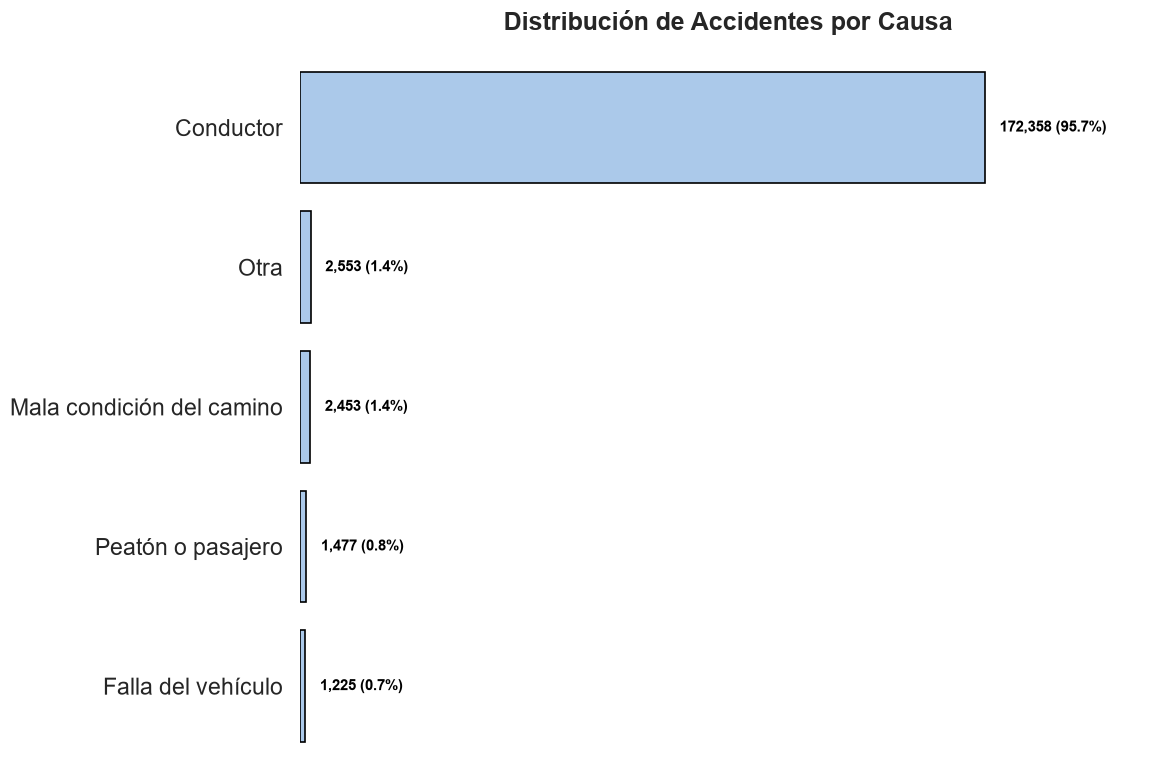

In [9]:


# 1. Aplicar el estilo de Seaborn
sns.set_theme(style="whitegrid", context="talk")
sns.set_palette("pastel")

# 2. Calcular los conteos y porcentajes
conteo_causas = df['CAUSAACCI'].value_counts(dropna=False)
total_causas = conteo_causas.sum()
porcentajes = (conteo_causas / total_causas * 100).round(1)

# 3. Crear la figura (más alta para que quepan todas las causas)
fig, ax = plt.subplots(figsize=(12, 8))

# 4. Dibujar el gráfico de barras HORIZONTAL
sns.barplot(
    x=conteo_causas.values, 
    y=conteo_causas.index, 
    ax=ax,
    edgecolor='black',
    linewidth=1.2
)

# 5. Añadir las etiquetas (conteo exacto y porcentaje)
for i, (valor, pct) in enumerate(zip(conteo_causas.values, porcentajes.values)):
    # En gráfico horizontal, el texto va a la derecha de la barra (valor + un margen)
    margen = total_causas * 0.015
    ax.text(
        valor + margen, i, 
        f' {valor:,} ({pct}%)', 
        ha='left', va='center', 
        fontweight='bold', fontsize=11, color='black'
    )

# 6. Ajustes estéticos finales
ax.set_title('Distribución de Accidentes por Causa', fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('') 
ax.set_ylabel('') 

# --- MODIFICACIÓN: Eliminar los valores del eje X (por ser barras horizontales) ---
ax.set_xticks([]) 

# Ajustar el límite del eje X para que las etiquetas no se corten
ax.set_xlim(0, conteo_causas.max() * 1.25)

# Quitar la cuadrícula en ambos ejes para un look más limpio
ax.grid(False) 

# Quitar los bordes (incluyendo el inferior, que es donde estaban los valores)
sns.despine(left=True, top=True, right=True, bottom=True)

plt.tight_layout()
plt.show()

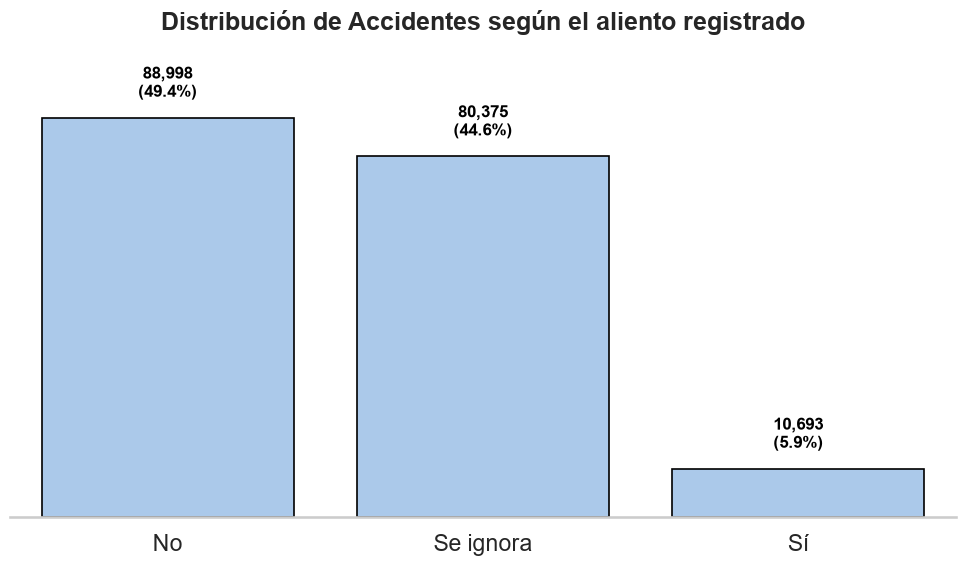

In [10]:
# 1. Aplicar el estilo de Seaborn
sns.set_theme(style="whitegrid", context="talk")
sns.set_palette("pastel")

# 2. Calcular los conteos y porcentajes
# (Usamos dropna=False por si hay valores nulos, para que no desaparezcan)
conteo_aliento = df['ALIENTO'].value_counts(dropna=False)
total = conteo_aliento.sum()
porcentajes = (conteo_aliento / total * 100).round(1)

# 3. Crear la figura
fig, ax = plt.subplots(figsize=(10, 6))

# 4. Dibujar el gráfico de barras
sns.barplot(
    x=conteo_aliento.index, 
    y=conteo_aliento.values, 
    ax=ax,
    edgecolor='black', # Borde negro para que resalten
    linewidth=1.2
)

# 5. Añadir las etiquetas con el conteo exacto y el porcentaje
for i, (valor, pct) in enumerate(zip(conteo_aliento.values, porcentajes.values)):
    # Posicionamos el texto un poco arriba de la barra (valor + 2% del total para dar aire)
    ax.text(
        i, valor + (total * 0.02), 
        f'{valor:,}\n({pct}%)', 
        ha='center', va='bottom', 
        fontweight='bold', fontsize=12, color='black'
    )

# 6. Ajustes estéticos finales
ax.set_title('Distribución de Accidentes según el aliento registrado', fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('') # Quitamos el título del eje X porque las categorías son obvias
ax.set_ylabel('')
ax.set_yticks([]) 

# Ajustar el límite del eje Y para que las etiquetas no se corten
ax.set_ylim(0, total * 0.15 if total * 0.15 > conteo_aliento.max() else conteo_aliento.max() * 1.15)

# Quitar las líneas de la cuadrícula en el eje X para que se vea más limpio
ax.grid(axis='x', visible=False)

# Quitar los bordes superior e izquierdo (opcional, se ve más moderno)
sns.despine(left=True, top=True)

plt.tight_layout()
plt.show()

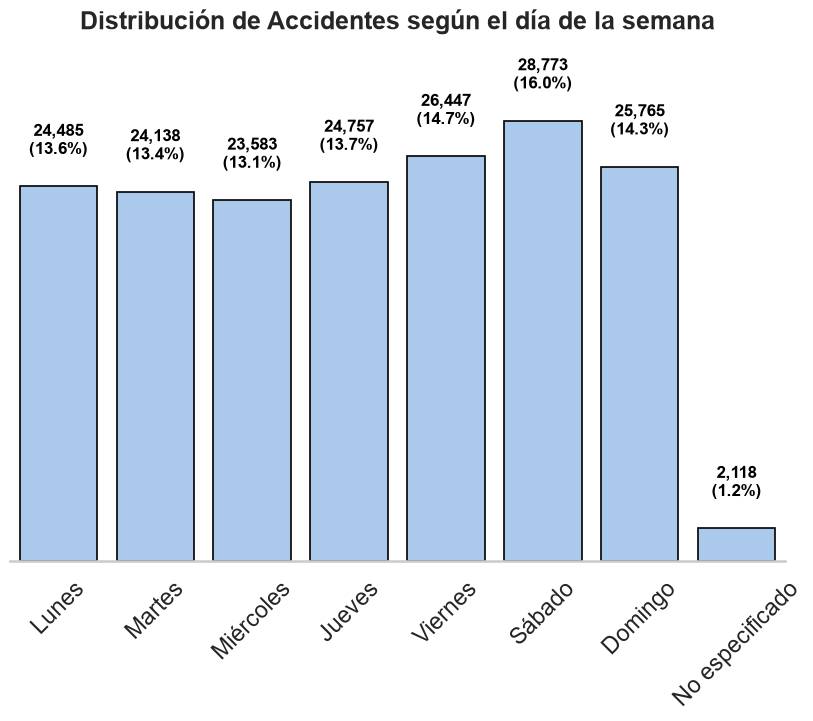

In [30]:
# 1. Aplicar el estilo de Seaborn
sns.set_theme(style="whitegrid", context="talk")
sns.set_palette("pastel")

# 2. Calcular los conteos y porcentajes

orden_dias = [
    "Lunes",
    "Martes",
    "Miércoles",
    "Jueves",
    "Viernes",
    "Sábado",
    "Domingo",
    "No especificado"
]

df['DIASEMANA'] = pd.Categorical(df['DIASEMANA'], categories=orden_dias, ordered=True)
conteo_dias_semana = df['DIASEMANA'].value_counts(sort=False)
total_dias = conteo_dias_semana.sum()
porcentajes_dias_semana = (conteo_dias_semana / total_dias * 100).round(1)

# 3. Crear la figura
fig, ax = plt.subplots(figsize=(10, 6))

# 4. Dibujar el gráfico de barras
sns.barplot(
    x=conteo_dias_semana.index, 
    y=conteo_dias_semana.values, 
    ax=ax,
    edgecolor='black', # Borde negro para que resalten
    linewidth=1.2
)

# 5. Añadir las etiquetas con el conteo exacto y el porcentaje
for i, (valor, pct) in enumerate(zip(conteo_dias_semana.values, porcentajes_dias_semana.values)):
    # Posicionamos el texto un poco arriba de la barra (valor + 2% del total para dar aire)
    ax.text(
        i, valor + (total * 0.01), 
        f'{valor:,}\n({pct}%)', 
        ha='center', va='bottom', 
        fontweight='bold', fontsize=12, color='black'
    )

# 6. Ajustes estéticos finales
ax.set_title('Distribución de Accidentes según el día de la semana', fontsize=18, fontweight='bold', pad=50)
ax.set_xlabel('') # Quitamos el título del eje X porque las categorías son obvias
ax.set_ylabel('') 
ax.set_yticks([]) 
plt.xticks(rotation=45)

# Quitar las líneas de la cuadrícula en el eje X para que se vea más limpio
ax.grid(axis='x', visible=False)

# Quitar los bordes superior e izquierdo (opcional, se ve más moderno)
sns.despine(left=True, top=True)

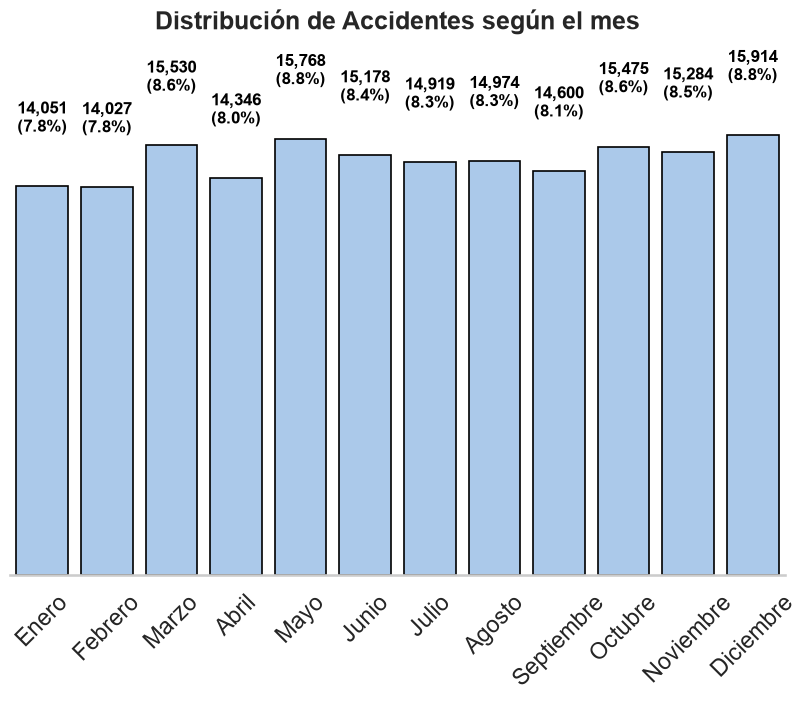

In [29]:
# 1. Aplicar el estilo de Seaborn
sns.set_theme(style="whitegrid", context="talk")
sns.set_palette("pastel")

# 2. Calcular los conteos y porcentajes

orden_mes = [
    "Enero",
    "Febrero",
    "Marzo",
    "Abril",
    "Mayo",
    "Junio",
    "Julio",
    "Agosto",
    "Septiembre",
    "Octubre",
    "Noviembre",
    "Diciembre"
]

df['MES'] = pd.Categorical(df['MES'], categories=orden_mes, ordered=True)
conteo_meses = df['MES'].value_counts(sort=False)
total_meses = conteo_meses.sum()
porcentajes_meses = (conteo_meses / total_meses * 100).round(1)

# 3. Crear la figura
fig, ax = plt.subplots(figsize=(10, 6))

# 4. Dibujar el gráfico de barras
sns.barplot(
    x=conteo_meses.index, 
    y=conteo_meses.values, 
    ax=ax,
    edgecolor='black', # Borde negro para que resalten
    linewidth=1.2
)

# 5. Añadir las etiquetas con el conteo exacto y el porcentaje
for i, (valor, pct) in enumerate(zip(conteo_meses.values, porcentajes_meses.values)):
    # Posicionamos el texto un poco arriba de la barra (valor + 2% del total para dar aire)
    ax.text(
        i, valor + (total * 0.01), 
        f'{valor:,}\n({pct}%)', 
        ha='center', va='bottom', 
        fontweight='bold', fontsize=12, color='black'
    )

# 6. Ajustes estéticos finales
ax.set_title('Distribución de Accidentes según el mes', fontsize=18, fontweight='bold', pad=60)
ax.set_xlabel('') # Quitamos el título del eje X porque las categorías son obvias
ax.set_ylabel('') 
ax.set_yticks([]) 
plt.xticks(rotation=45)

# Quitar las líneas de la cuadrícula en el eje X para que se vea más limpio
ax.grid(axis='x', visible=False)

# Quitar los bordes superior e izquierdo (opcional, se ve más moderno)
sns.despine(left=True, top=True)

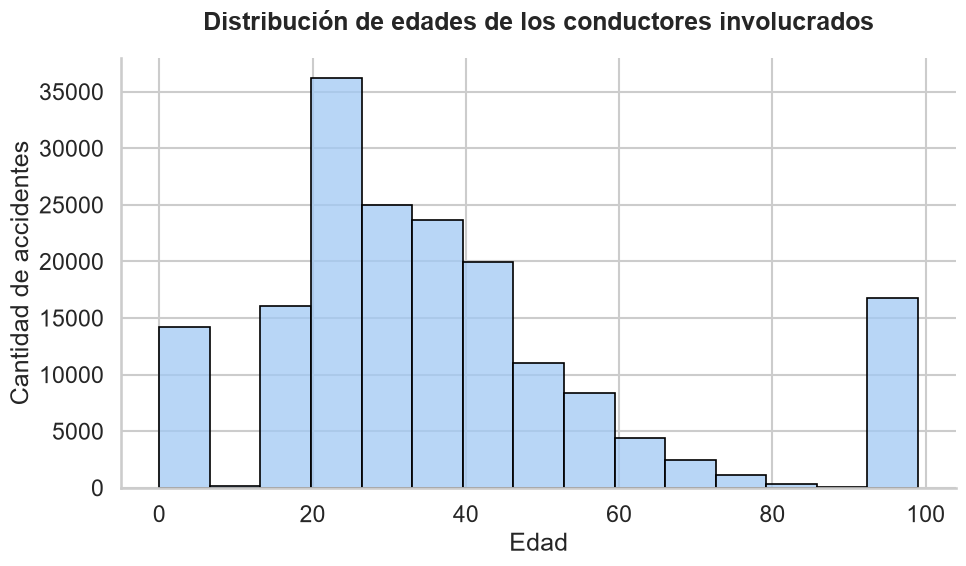

In [87]:
# Estilo
sns.set_theme(style="whitegrid", context="talk")
sns.set_palette("pastel")

# Figura
fig, ax = plt.subplots(figsize=(10, 6))

# Histograma
sns.histplot(
    df["ID_EDAD"],
    bins=15,
    kde=False,
    edgecolor='black',
    linewidth=1.2,
    ax=ax
)

# Títulos
ax.set_title(
    'Distribución de edades de los conductores involucrados',
    fontsize=18,
    fontweight='bold',
    pad=20
)

ax.set_xlabel('Edad')
ax.set_ylabel('Cantidad de accidentes')

sns.despine()

plt.tight_layout()
plt.show()

El histograma tiene muchos valores de 0 y 99, se hace un gráfico de barras con ambas columnas aparte y otro que elimina ambos valores

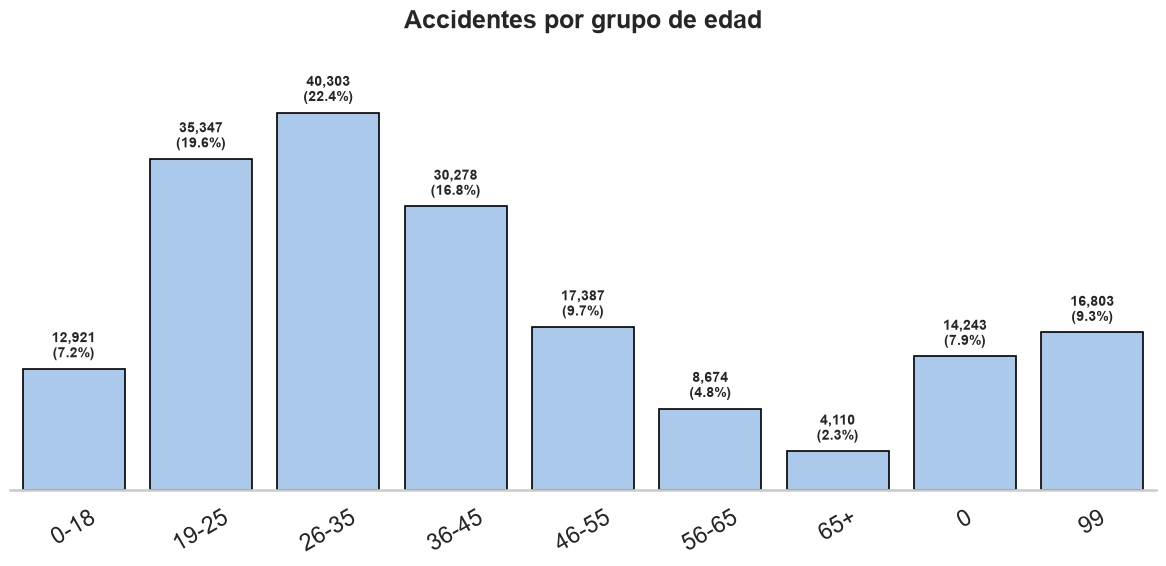

In [88]:
edad_grupo = pd.Series(index=df.index, dtype='object')

# Categorías especiales
edad_grupo[df['ID_EDAD'] == 0] = '0'
edad_grupo[df['ID_EDAD'] == 99] = '99'

# Edades válidas
mask = ~df['ID_EDAD'].isin([0, 99])

edad_grupo.loc[mask] = pd.cut(
    df.loc[mask, 'ID_EDAD'],
    bins=[0, 18, 25, 35, 45, 55, 65, 100],
    labels=[
        '0-18',
        '19-25',
        '26-35',
        '36-45',
        '46-55',
        '56-65',
        '65+'
    ]
).astype(str)

# Orden deseado
orden = [
    '0-18',
    '19-25',
    '26-35',
    '36-45',
    '46-55',
    '56-65',
    '65+',
    '0',
    '99'
]

conteos = edad_grupo.value_counts().reindex(orden).fillna(0)

porcentajes = (conteos / conteos.sum() * 100).round(1)

sns.set_theme(style="whitegrid", context="talk")
sns.set_palette("pastel")

fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    x=conteos.index,
    y=conteos.values,
    ax=ax,
    edgecolor='black',
    linewidth=1.2
)

# Etiquetas
for i, (valor, pct) in enumerate(zip(conteos.values, porcentajes.values)):
    ax.text(
        i,
        valor + conteos.max()*0.02,
        f'{int(valor):,}\n({pct}%)',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

ax.set_title(
    'Accidentes por grupo de edad',
    fontsize=18,
    fontweight='bold',
    pad=20
)

ax.set_xlabel('')
ax.set_ylabel('')

ax.set_yticks([])

ax.set_ylim(0, conteos.max()*1.15)

ax.tick_params(axis='x', rotation=30)

ax.grid(axis='x', visible=False)

sns.despine(left=True, top=True)

plt.tight_layout()
plt.show()

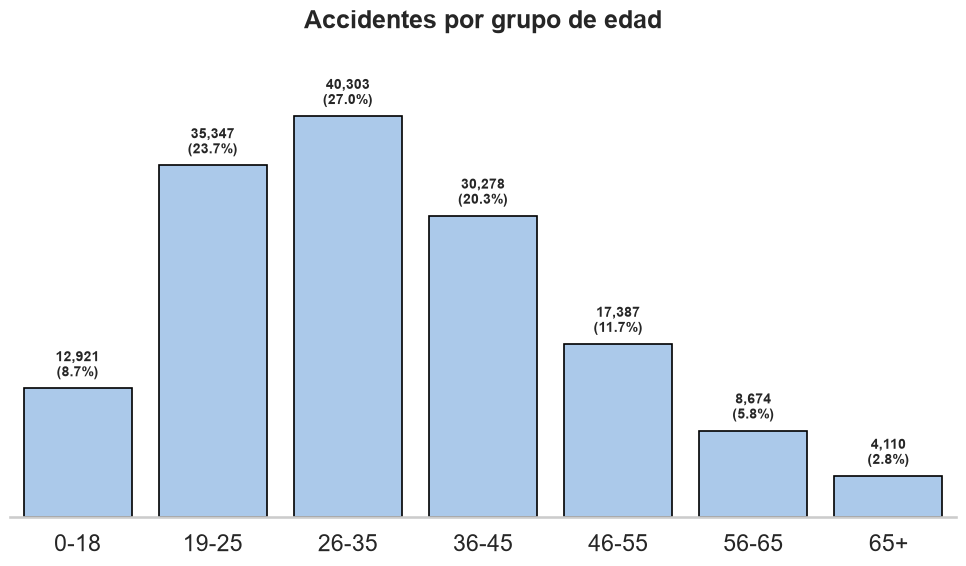

In [82]:
#Quitamos a aquellos con edad 0 y 99
edades = df['ID_EDAD'].replace([0, 99], np.nan)

bins = [0, 18, 25, 35, 45, 55, 65, 100]
labels = [
    '0-18',
    '19-25',
    '26-35',
    '36-45',
    '46-55',
    '56-65',
    '65+'
]

grupos = pd.cut(
    edades,
    bins=bins,
    labels=labels
)

conteos = grupos.value_counts().sort_index()
porcentajes = (conteos / conteos.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    x=conteos.index,
    y=conteos.values,
    ax=ax,
    edgecolor='black',
    linewidth=1.2
)

for i, (valor, pct) in enumerate(zip(conteos.values, porcentajes.values)):
    ax.text(
        i,
        valor + conteos.max()*0.02,
        f'{int(valor):,}\n({pct}%)',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

ax.set_title(
    'Accidentes por grupo de edad',
    fontsize=18,
    fontweight='bold',
    pad=20
)

ax.set_xlabel('')
ax.set_ylabel('')
ax.set_yticks([]) 

ax.set_ylim(0, conteos.max()*1.15)

ax.grid(axis='x', visible=False)

sns.despine(left=True, top=True)

plt.tight_layout()
plt.show()

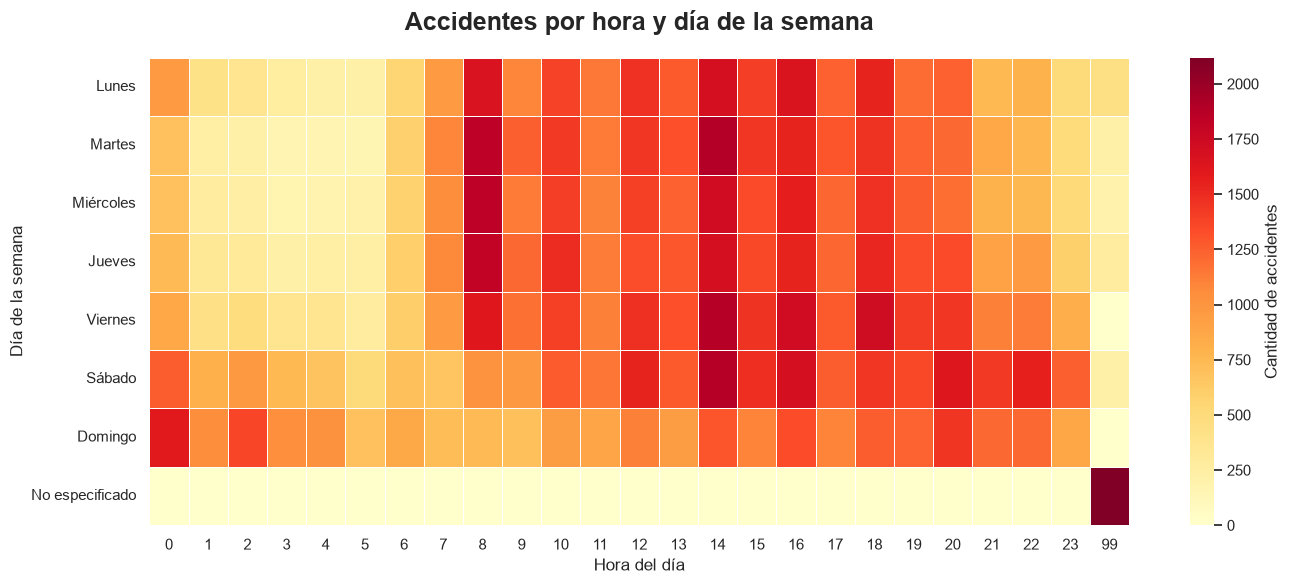

In [90]:
sns.set_theme(style="white")

tabla_horas = pd.crosstab(
    df['DIASEMANA'],
    df['ID_HORA']
)

tabla_horas = tabla_horas.reindex(orden_dias)

fig, ax = plt.subplots(figsize=(14, 6))

sns.heatmap(
    tabla_horas,
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={'label': 'Cantidad de accidentes'},
    ax=ax
)

ax.set_title(
    'Accidentes por hora y día de la semana',
    fontsize=18,
    fontweight='bold',
    pad=20
)

ax.set_xlabel('Hora del día')
ax.set_ylabel('Día de la semana')

plt.tight_layout()
plt.show()

Eliminamos esos dias y horas no especificados

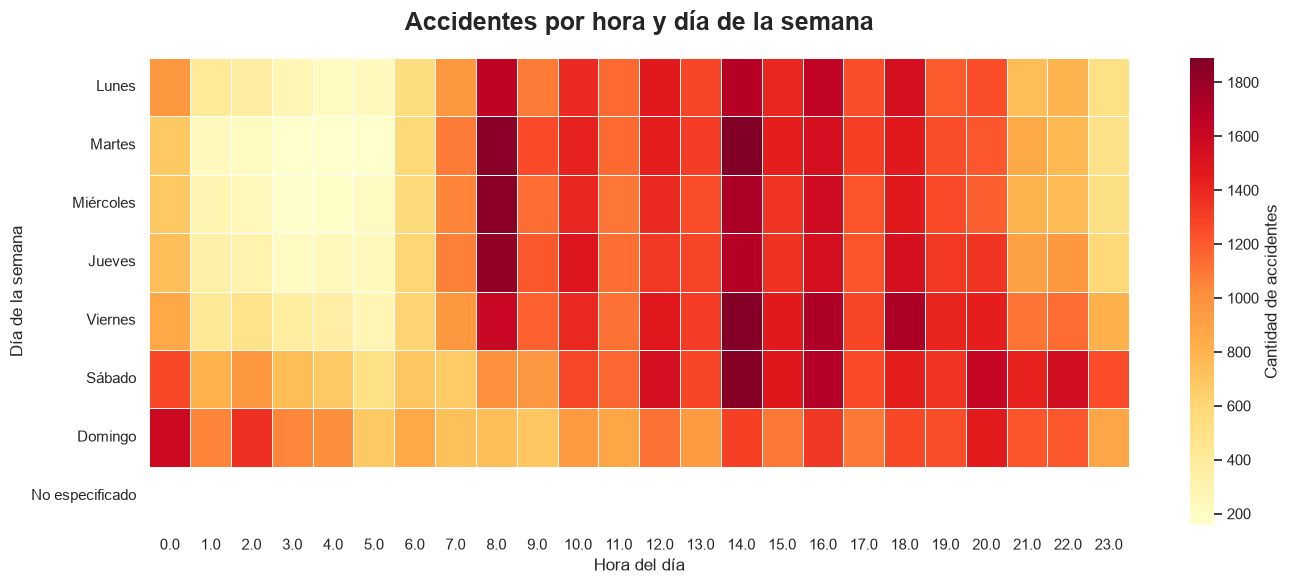

In [101]:
horas_dia = df['ID_HORA'].replace([99], np.nan)
dia_semana = df['DIASEMANA'].replace('No especificado',np.nan)

sns.set_theme(style="white")

tabla_horas = pd.crosstab(
    dia_semana,
    horas_dia
)

tabla_horas = tabla_horas.reindex(orden_dias)

fig, ax = plt.subplots(figsize=(14, 6))

sns.heatmap(
    tabla_horas,
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={'label': 'Cantidad de accidentes'},
    ax=ax
)

ax.set_title(
    'Accidentes por hora y día de la semana',
    fontsize=18,
    fontweight='bold',
    pad=20
)

ax.set_xlabel('Hora del día')
ax.set_ylabel('Día de la semana')

plt.tight_layout()
plt.show()